# EDA & Preprocessing: Telco Customer Churn

**Data Understanding & Preprocessing**
1. Setup & Load
2. Schema Check
3. Missing Value: Phát hiện + Xử lý
4. Outlier: Phát hiện + Quyết định xử lý
5. Class Imbalance
6. Bảng tổng hợp & Visualization

## 1. Setup & Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
import os

FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)


In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"Shape: {df.shape}")
df.head(5)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv") 
mask = raw['TotalCharges'].str.strip() == ''
print(raw.loc[mask, ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].head(11))

      tenure  MonthlyCharges TotalCharges Churn
488        0           52.55                 No
753        0           20.25                 No
936        0           80.85                 No
1082       0           25.75                 No
1340       0           56.05                 No
3331       0           19.85                 No
3826       0           25.35                 No
4380       0           20.00                 No
5218       0           19.70                 No
6670       0           73.35                 No
6754       0           61.90                 No


## 2. Schema Check

In [4]:
def schema_report(df):
    print(f"Shape: {df.shape[0]} rows x {df.shape[1]} cols")
    print("\nDtypes:")
    print(df.dtypes)
    print("\nNull count (raw, before cleaning):")
    print(df.isnull().sum().sum(), "tong gia tri null (theo pandas)")

schema_report(df)


Shape: 7043 rows x 21 cols

Dtypes:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Null count (raw, before cleaning):
0 tong gia tri null (theo pandas)


- Bộ dữ liệu gồm **7.043 dòng và 21 cột**.
- Cột TotalCharges có kiểu dữ liệu object(dạng chuỗi), nên cần kiểm tra xem có chứa giá trị thiếu hay không.
- Phần lớn các cột còn lại là biến phân loại, trong đó Churn là biến mục tiêu cần dự đoán.
- Dùng lệnh df.isnull().sum() để kiểm tra số lượng giá trị thiếu ở từng cột. Tuy nhiên, chưa phát hiện được các giá trị thiếu trong TotalCharges vì chúng đang được lưu dưới dạng chuỗi khoảng trắng " ", thay vì giá trị thiếu NaN.

In [5]:
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.describe(include='object')


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [7]:
cat_check_cols = ['InternetService', 'OnlineSecurity', 'OnlineBackup',
                   'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for c in cat_check_cols:
    print(f"{c}: {df[c].unique()}")

InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']


## 3. Missing Value: Phát hiện + Xử lý

In [8]:
def clean_total_charges(df):
    df = df.copy()
    blank_mask = df['TotalCharges'].astype(str).str.strip().eq('')
    blank_count = int(blank_mask.sum())

    # Kiểm tra trước khi điền 0: các dòng trống có đúng là khách mới (tenure = 0) không?
    blank_with_tenure0 = int((df.loc[blank_mask, 'tenure'] == 0).sum())
    blank_churn_yes = int((df.loc[blank_mask, 'Churn'] == 'Yes').sum())

    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    missing_after_convert = int(df['TotalCharges'].isna().sum())

    df['TotalCharges'] = df['TotalCharges'].fillna(0)

    report = pd.DataFrame({
        'Metric': ['Blank strings in TotalCharges', 'NaN after pd.to_numeric', 'Rows filled with 0',
                   'Blank rows with tenure = 0', 'Blank rows with Churn = Yes'],
        'Value': [blank_count, missing_after_convert, missing_after_convert,
                  blank_with_tenure0, blank_churn_yes]
    })
    return df, report

df, missing_report = clean_total_charges(df)
missing_report

,Metric,Value
0,Blank strings in TotalCharges,11
1,NaN after pd.to_numeric,11
2,Rows filled with 0,11
3,Blank rows with tenure = 0,11
4,Blank rows with Churn = Yes,0


- Cột TotalCharges có 11 dòng chứa chuỗi khoảng trắng " ". Các dòng này đều có tenure = 0, nghĩa là khách hàng chưa sử dụng dịch vụ được ghi nhận trong dữ liệu và chưa phát sinh tổng chi phí sử dụng.
- Thay các giá trị này bằng 0 thay vì xóa các dòng dữ liệu, vì giá trị 0 phù hợp với trường hợp khách hàng chưa phát sinh chi phí.
- Sau khi xử lý, giữ nguyên toàn bộ 7.043 dòng dữ liệu, tránh làm mất thông tin của các khách hàng này.

**Hình 1: Dòng thiếu TotalCharges đều là khách mới**
- Các điểm đỏ là khách có tenure = 0: chưa qua tháng thanh toán nào nên chưa có tổng chi phí. Vì vậy điền giá trị là 0, không phải dữ liệu bị mất.

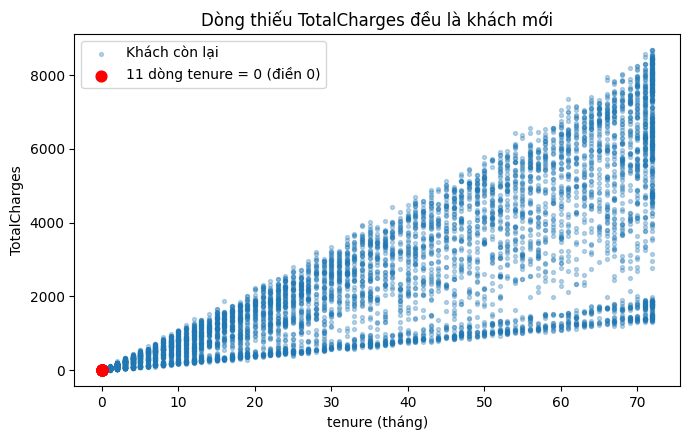

In [9]:
new = df['tenure'] == 0
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df.loc[~new, 'tenure'], df.loc[~new, 'TotalCharges'], s=8, alpha=0.3, label='Khách còn lại')
ax.scatter(df.loc[new, 'tenure'], df.loc[new, 'TotalCharges'], s=60, color='red',
           label=f'{new.sum()} dòng tenure = 0 (điền 0)')
ax.set_xlabel('tenure (tháng)'); ax.set_ylabel('TotalCharges')
ax.set_title('Dòng thiếu TotalCharges đều là khách mới')
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_missing_totalcharges.png", dpi=150, bbox_inches='tight')
plt.show()

In [10]:
df[['tenure', 'MonthlyCharges', 'TotalCharges']].isnull().sum()


tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64

## 4. Outlier: Phát hiện + Quyết định xử lý

In [11]:
def outlier_report_iqr(df, cols):
    """Dem outlier theo IQR cho tung cot so."""
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_outliers = ((df[c] < lower) | (df[c] > upper)).sum()
        rows.append({'Column': c, 'Q1': q1, 'Q3': q3, 'Lower bound': lower,
                     'Upper bound': upper, 'N outliers (IQR)': n_outliers,
                     'N negative values': (df[c] < 0).sum()})
    return pd.DataFrame(rows)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
outlier_report = outlier_report_iqr(df, num_cols)
outlier_report


,Column,Q1,Q3,Lower bound,Upper bound,N outliers (IQR),N negative values
0,tenure,9.00,55.00,-60.000,124.000,0,0
1,MonthlyCharges,35.50,89.85,-46.025,171.375,0,0
2,TotalCharges,398.55,3786.60,-4683.525,8868.675,0,0


In [12]:
# Giá trị nhỏ nhất và lớn nhất thực tế, để đối chiếu với Lower/Upper bound 
df[num_cols].agg(['min', 'max']).T

,min,max
tenure,0.00,72.00
MonthlyCharges,18.25,118.75
TotalCharges,0.00,8684.80


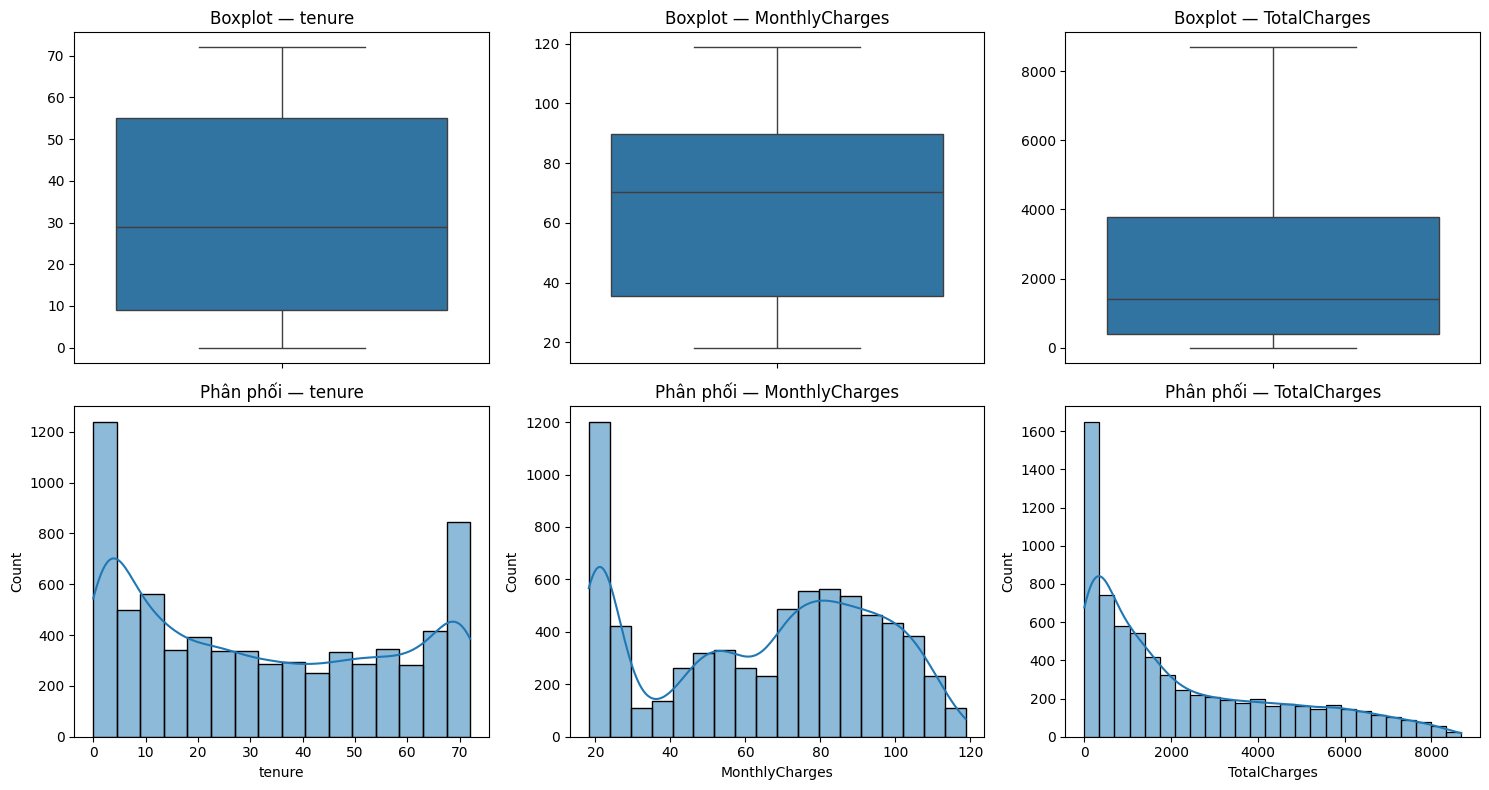

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.boxplot(y=df[c], ax=axes[0, i]); axes[0, i].set_title(f'Boxplot — {c}'); axes[0, i].set_ylabel('')
    sns.histplot(df[c], kde=True, ax=axes[1, i]); axes[1, i].set_title(f'Phân phối — {c}')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_outlier_numeric.png", dpi=150, bbox_inches='tight')
plt.show()

- Không phát hiện giá trị âm ở ba cột tenure, MonthlyCharges và TotalCharges.
- Theo phương pháp IQR, cả ba cột đều có 0 giá trị ngoại lệ (outlier), tức là không có giá trị nào nằm ngoài khoảng từ Lower bound đến Upper bound. Ví dụ, cột tenurecó giá trị từ 0 đến 72 tháng, đều nằm trong khoảng kiểm tra với cận trên là 124.
- Vì không phát hiện giá trị ngoại lệ theo tiêu chí IQR, nhóm không xóa hoặc cắt bớt giá trị nào. Các biến số sẽ được chuẩn hóa hoặc điều chỉnh thang đo ở bước tiền xử lý tiếp theo.

## 5. Class Imbalance

In [14]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

imbalance_report = pd.DataFrame({
    'Count': churn_counts,
    'Percentage (%)': churn_pct.round(3)
})
imbalance_report


,Count,Percentage (%)
Churn,,
No,5174,73.463
Yes,1869,26.537


- Tỷ lệ khách hàng không rời bỏ dịch vụ (Churn = No) là 73,463%, trong khi tỷ lệ khách hàng rời bỏ dịch vụ (Churn = Yes) là 26,537%, tương đương khoảng 26,5%.
- Bộ dữ liệu có tình trạng mất cân bằng lớp ở mức vừa phải. Nhóm lựa chọn phương pháp `Class Weight` thay vì SMOTE để tăng mức độ chú ý của mô hình đối với nhóm khách hàng rời bỏ dịch vụ, mà không cần tạo thêm dữ liệu nhân tạo.
- Trọng số được tính dựa trên tập huấn luyện ở mục 7 và lưu lại để sử dụng khi huấn luyện mô hình. Class Weight được áp dụng trong bước huấn luyện, không phải bước tiền xử lý dữ liệu.

## 6. Bảng tổng hợp & Visualization

In [15]:
summary_table = pd.DataFrame({
    'Hang muc': ['Tong dong (sau xu ly missing)', 'Tong cot', 'Missing xu ly (TotalCharges)',
                 'Outlier am (tenure/MonthlyCharges/TotalCharges)', 'Ty le Churn = Yes',
                 'Ty le Churn = No'],
    'Gia tri': [df.shape[0], df.shape[1], int(missing_report.loc[2, 'Value']), int(outlier_report['N negative values'].sum()),
                f"{churn_pct['Yes']:.2f}%", f"{churn_pct['No']:.2f}%"]
})
summary_table

,Hang muc,Gia tri
0,Tong dong (sau xu ly missing),7043
1,Tong cot,21
2,Missing xu ly (TotalCharges),11
3,Outlier am (tenure/MonthlyCharges/TotalCharges),0
4,Ty le Churn = Yes,26.54%
5,Ty le Churn = No,73.46%


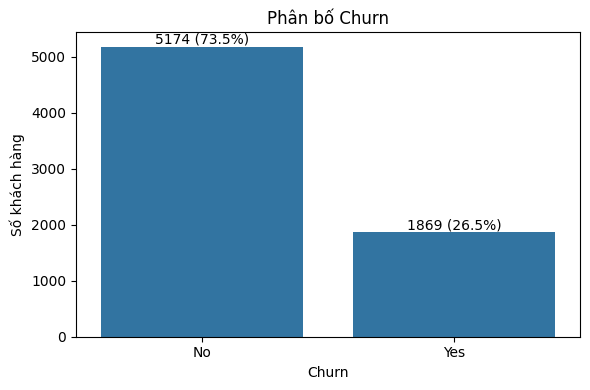

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=churn_counts.index.astype(str), y=churn_counts.values, ax=ax)
for i, (n, p) in enumerate(zip(churn_counts.values, churn_pct.values)):
    ax.text(i, n, f"{n} ({p:.1f}%)", ha='center', va='bottom')
ax.set_title('Phân bố Churn')
ax.set_xlabel('Churn'); ax.set_ylabel('Số khách hàng')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_churn_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

## 7. Preprocessing Pipeline

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
import joblib

# chuẩn bị target và bỏ cột thừa
if not pd.api.types.is_numeric_dtype(df['Churn']):
    df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
assert df['Churn'].isna().sum() == 0, "Churn có NaN sau khi map, kiểm tra lại dữ liệu"
assert set(df['Churn'].unique()) == {0, 1}

X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

# chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# xác định cột phân loại / số
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols)
])

pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

X_train_processed = pipeline.fit_transform(X_train) 
X_test_processed = pipeline.transform(X_test)        

print(f"X_train_processed shape: {X_train_processed.shape}")
print(f"X_test_processed shape: {X_test_processed.shape}")

# tính class weight từ y_train
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
print(f"Class weight: {class_weight_dict}")
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
print(f"Số lượng feature: {len(feature_names)}")
print(feature_names)

X_train_processed shape: (5634, 40)
X_test_processed shape: (1409, 40)
Class weight: {0: 0.6805991785455424, 1: 1.8842809364548494}
Số lượng feature: 40
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Male' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No' 'cat__OnlineBackup_No internet service'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_No'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No' 'cat__TechSupport_No internet service'
 'cat__TechSupport_Yes' 'cat__StreamingTV_No'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No' 'cat__StreamingMovies_No

- Mã hóa bằng One-Hot Encoding với drop='if_binary', thu được 40 features.
- Giữ nguyên cách mã hóa này để thống nhất với quá trình huấn luyện và đánh giá mô hình đã thực hiện.

**Cách chia tập dữ liệu:**
- **Tập Train (80%)**: 5.634 dòng, dùng để huấn luyện và lựa chọn mô hình.
- **Tập Test (20%)**: 1.409 dòng, được chia một lần bằng stratify(chia phân tầng) để giữ tỷ lệ Churn giữa các tập, chỉ dùng đánh giá cuối cùng.
- **Tập Validation**: Không tách riêng mà sử dụng phương pháp Stratified 5-Fold Cross-Validation trên tập Train để đánh giá và điều chỉnh mô hình.
- **Tiền xử lý**: Scaler và Encoder chỉ được fit trên dữ liệu huấn luyện, tập Test chỉ được transform.

**Hình 4: Tỉ lệ churn ở Train và Test**

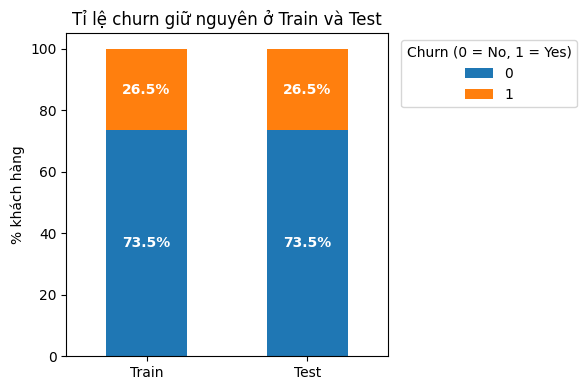

In [18]:
split = pd.DataFrame({'Train': y_train.value_counts(normalize=True),
                      'Test': y_test.value_counts(normalize=True)}).mul(100)
ax = split.T.plot(kind='bar', stacked=True, figsize=(6, 4), rot=0)
for p in ax.patches:
    ax.text(p.get_x() + p.get_width() / 2, p.get_y() + p.get_height() / 2,
            f'{p.get_height():.1f}%', ha='center', va='center', color='white', fontweight='bold')
ax.set_ylabel('% khách hàng'); ax.set_title('Tỉ lệ churn giữ nguyên ở Train và Test')
ax.legend(title='Churn (0 = No, 1 = Yes)', loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_split_stratify.png", dpi=150, bbox_inches='tight')
plt.show()

**Hình 5: Ba biến số trước và sau StandardScaler** (trên tập train)

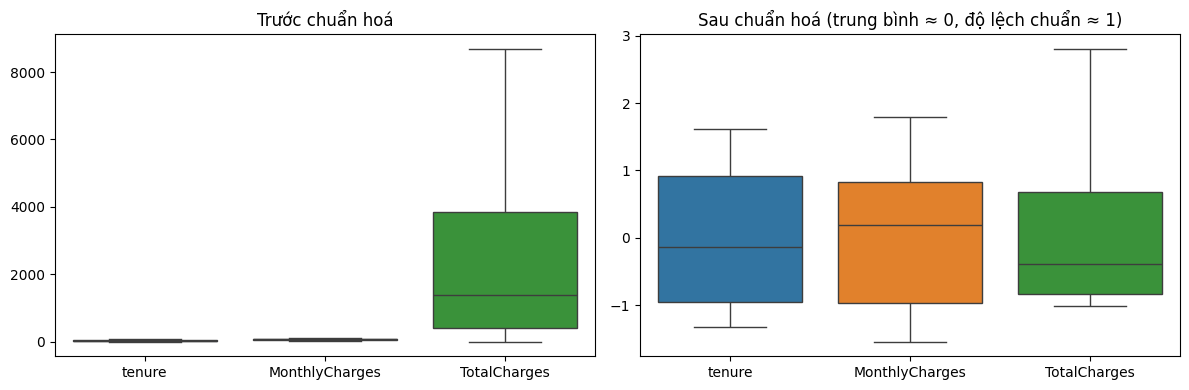

In [19]:
cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
idx = [list(feature_names).index(f'num__{c}') for c in cols]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=X_train[cols], ax=axes[0]); axes[0].set_title('Trước chuẩn hoá')
sns.boxplot(data=pd.DataFrame(X_train_processed[:, idx], columns=cols), ax=axes[1])
axes[1].set_title('Sau chuẩn hoá (trung bình ≈ 0, độ lệch chuẩn ≈ 1)')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_scaling_before_after.png", dpi=150, bbox_inches='tight')
plt.show()

**Kiểm tra từ file CSV gốc đến dữ liệu sẵn train:**: Đọc lại file gốc, làm sạch bằng clean_raw_features rồi dùng pipeline.transform để kiểm tra kết quả có khớp dữ liệu đã xử lý hay không. Quy trình này cũng áp dụng cho khách hàng mới trên dashboard.

In [20]:
def clean_raw_features(df_in):
    """Làm sạch dữ liệu THÔ trước khi đưa vào pipeline đã lưu.

    - TotalCharges: ép sang số, ô trống (khách mới, chưa có hoá đơn) điền 0.
    - Bỏ customerID và Churn nếu có.
    """
    out = df_in.copy()
    out['TotalCharges'] = pd.to_numeric(out['TotalCharges'], errors='coerce').fillna(0)
    return out.drop(columns=['customerID', 'Churn'], errors='ignore')


raw = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
X_all = clean_raw_features(raw)
y_all = raw['Churn'].map({'Yes': 1, 'No': 0})

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)

def to_dense(a):
    return a.toarray() if hasattr(a, 'toarray') else a

check_train = to_dense(pipeline.transform(Xr_train))
check_test = to_dense(pipeline.transform(Xr_test))

assert not np.isnan(check_train).any() and not np.isnan(check_test).any(), "Còn NaN sau transform"
np.testing.assert_allclose(check_train, to_dense(X_train_processed), rtol=1e-7, atol=1e-9)
np.testing.assert_allclose(check_test, to_dense(X_test_processed), rtol=1e-7, atol=1e-9)
assert np.array_equal(yr_train.to_numpy(), y_train.to_numpy())
assert np.array_equal(yr_test.to_numpy(), y_test.to_numpy())
print("OK: CSV gốc -> clean_raw_features -> pipeline.transform cho đúng dữ liệu đã lưu.")
print("Shape train/test:", check_train.shape, check_test.shape, "| NaN: 0")

OK: CSV gốc -> clean_raw_features -> pipeline.transform cho đúng dữ liệu đã lưu.
Shape train/test: (5634, 40) (1409, 40) | NaN: 0


**Quy ước bàn giao cho Vai trò 3 và 4:**
- `preprocessing_pipeline.pkl` chỉ gồm bước encode + chuẩn hoá (`ColumnTransformer`). Nó **không** tự làm sạch `TotalCharges`
  và không mã hoá cột `Churn`.
- Với dữ liệu thô, phải chạy theo thứ tự: (1) `clean_raw_features(df)` để ép `TotalCharges` sang số và bỏ `customerID`;
  (2) `pipeline.transform(X)`. Cột `Churn` mã hoá riêng: Yes = 1, No = 0.
- Các file `.npy` và `y_*.csv` là kết quả đã chạy sẵn từ đúng quy trình trên; dùng trực tiếp được.
- `class_weight.pkl` chỉ là trọng số đã tính. Chưa mô hình nào tự dùng nó; việc áp dụng nằm ở bước huấn luyện
  (`class_weight` của `DecisionTreeClassifier`; KNN và `GaussianNB` không có tham số này).
- File `.pkl` được lưu bằng một phiên bản scikit-learn cụ thể; cả nhóm nên dùng cùng phiên bản (ghi vào `requirements.txt`).

In [21]:
# Lưu pipeline và dữ liệu đã xử lý để các bước sau còn dùng lại, không chạy lại từ đầu
joblib.dump(pipeline, '../data/preprocessing_pipeline.pkl')
joblib.dump(class_weight_dict, '../data/class_weight.pkl')
joblib.dump(feature_names, '../data/feature_names.pkl')

np.save('../data/X_train_processed.npy', X_train_processed)
np.save('../data/X_test_processed.npy', X_test_processed)
y_train.to_csv('../data/y_train.csv', index=False)
y_test.to_csv('../data/y_test.csv', index=False)